# مقارنة الـ Optimizers في تدريب Neural Networks
## SGD vs SGD+Momentum vs RMSprop vs Adam vs AdamW

الهدف: نشوف بعيننا الفرق في:
1. سرعة التقارب (Convergence)
2. الاستقرار (Stability)
3. جودة الحل النهائي (Final Loss)
4. سلوك الـ Learning Rate

هنستخدم نفس الموديل ونفس الداتا ونفس الـ seed عشان المقارنة تكون عادلة.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time

# ثوابت
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
print(f"PyTorch version: {torch.__version__}")

Using device: cuda
PyTorch version: 2.8.0+cu128


## 1. تجهيز الداتا
هنستخدم `make_moons` لأنها non-linear وبتحتاج الموديل يتعلم decision boundary منحني.

In [3]:
def prepare_data(n_samples=3000, noise=0.2):
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=SEED)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED
    )
    return (
        torch.FloatTensor(X_train).to(DEVICE),
        torch.LongTensor(y_train).to(DEVICE),
        torch.FloatTensor(X_test).to(DEVICE),
        torch.LongTensor(y_test).to(DEVICE),
        X, y
    )

X_train, y_train, X_test, y_test, X_all, y_all = prepare_data()

print(f"Train size: {X_train.shape}")
print(f"Test size:  {X_test.shape}")
print(f"Classes:    {torch.unique(y_train).tolist()}")

Train size: torch.Size([2400, 2])
Test size:  torch.Size([600, 2])
Classes:    [0, 1]


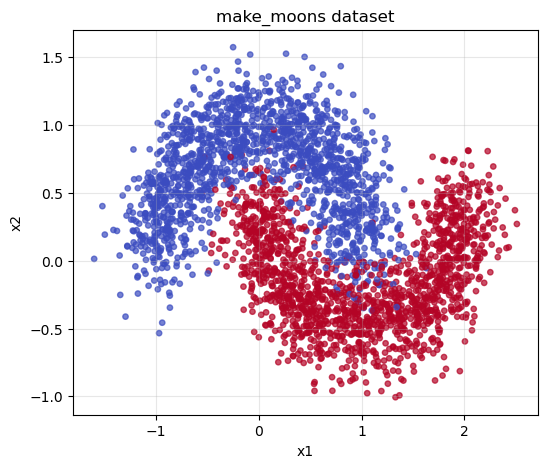

In [4]:
plt.figure(figsize=(6, 5))
plt.scatter(X_all[:, 0], X_all[:, 1], c=y_all, cmap="coolwarm", s=15, alpha=0.7)
plt.title("make_moons dataset")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 2. تعريف الموديل والـ Optimizers
نفس الشبكة بالظبط لكل التجارب — التغيير الوحيد هو الـ optimizer.

In [5]:
def make_model():
    torch.manual_seed(SEED)   # نفس البداية لكل التجارب
    return nn.Sequential(
        nn.Linear(2, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 2)
    ).to(DEVICE)

In [6]:
def get_optimizer(name, model):
    params = model.parameters()
    if name == "SGD":
        return optim.SGD(params, lr=0.01)
    elif name == "SGD+Momentum":
        return optim.SGD(params, lr=0.01, momentum=0.9)
    elif name == "RMSprop":
        return optim.RMSprop(params, lr=0.001)
    elif name == "Adam":
        return optim.Adam(params, lr=0.001)
    elif name == "AdamW":
        return optim.AdamW(params, lr=0.001, weight_decay=0.01)
    else:
        raise ValueError(f"Unknown optimizer: {name}")

OPTIMIZER_NAMES = ["SGD", "SGD+Momentum", "RMSprop", "Adam", "AdamW"]

## 3. حلقة التدريب
هنخزن الـ train loss و test accuracy لكل epoch.

In [7]:
def train_model(optimizer_name, epochs=150, verbose=False):
    model = make_model()
    opt = get_optimizer(optimizer_name, model)
    criterion = nn.CrossEntropyLoss()
    
    history = {
        "epoch": [],
        "train_loss": [],
        "test_loss": [],
        "test_acc": []
    }
    
    start = time.time()
    for epoch in range(epochs):
        # ---- Train ----
        model.train()
        opt.zero_grad()
        out = model(X_train)
        loss = criterion(out, y_train)
        loss.backward()
        opt.step()
        
        # ---- Eval ----
        model.eval()
        with torch.no_grad():
            train_loss = criterion(model(X_train), y_train).item()
            test_logits = model(X_test)
            test_loss = criterion(test_logits, y_test).item()
            test_acc = (test_logits.argmax(1) == y_test).float().mean().item()
        
        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        
        if verbose and epoch % 30 == 0:
            print(f"[{optimizer_name}] Epoch {epoch:3d} | "
                  f"train_loss={train_loss:.4f} | "
                  f"test_acc={test_acc:.4f}")
    
    elapsed = time.time() - start
    return model, history, elapsed

## 4. شغّل كل الـ Optimizers وقارن

In [8]:
EPOCHS = 150
results = {}
models = {}
times = {}

for name in OPTIMIZER_NAMES:
    print(f"\n{'='*50}")
    print(f"Training with {name}...")
    print('='*50)
    model, history, elapsed = train_model(name, epochs=EPOCHS, verbose=True)
    results[name] = history
    models[name] = model
    times[name] = elapsed
    print(f"✅ {name} finished in {elapsed:.2f}s | "
          f"final_acc={history['test_acc'][-1]:.4f}")


Training with SGD...
[SGD] Epoch   0 | train_loss=0.7029 | test_acc=0.4533
[SGD] Epoch  30 | train_loss=0.6783 | test_acc=0.4533
[SGD] Epoch  60 | train_loss=0.6560 | test_acc=0.4533
[SGD] Epoch  90 | train_loss=0.6326 | test_acc=0.6450
[SGD] Epoch 120 | train_loss=0.6063 | test_acc=0.7750
✅ SGD finished in 0.39s | final_acc=0.7900

Training with SGD+Momentum...
[SGD+Momentum] Epoch   0 | train_loss=0.7029 | test_acc=0.4533
[SGD+Momentum] Epoch  30 | train_loss=0.5344 | test_acc=0.7967
[SGD+Momentum] Epoch  60 | train_loss=0.3441 | test_acc=0.8367
[SGD+Momentum] Epoch  90 | train_loss=0.2974 | test_acc=0.8683
[SGD+Momentum] Epoch 120 | train_loss=0.2759 | test_acc=0.8767
✅ SGD+Momentum finished in 0.17s | final_acc=0.8883

Training with RMSprop...
[RMSprop] Epoch   0 | train_loss=0.6058 | test_acc=0.7450
[RMSprop] Epoch  30 | train_loss=0.1308 | test_acc=0.9617
[RMSprop] Epoch  60 | train_loss=0.0915 | test_acc=0.9633
[RMSprop] Epoch  90 | train_loss=0.0852 | test_acc=0.9650
[RMSprop]

## 5. الرسم — Loss Curves

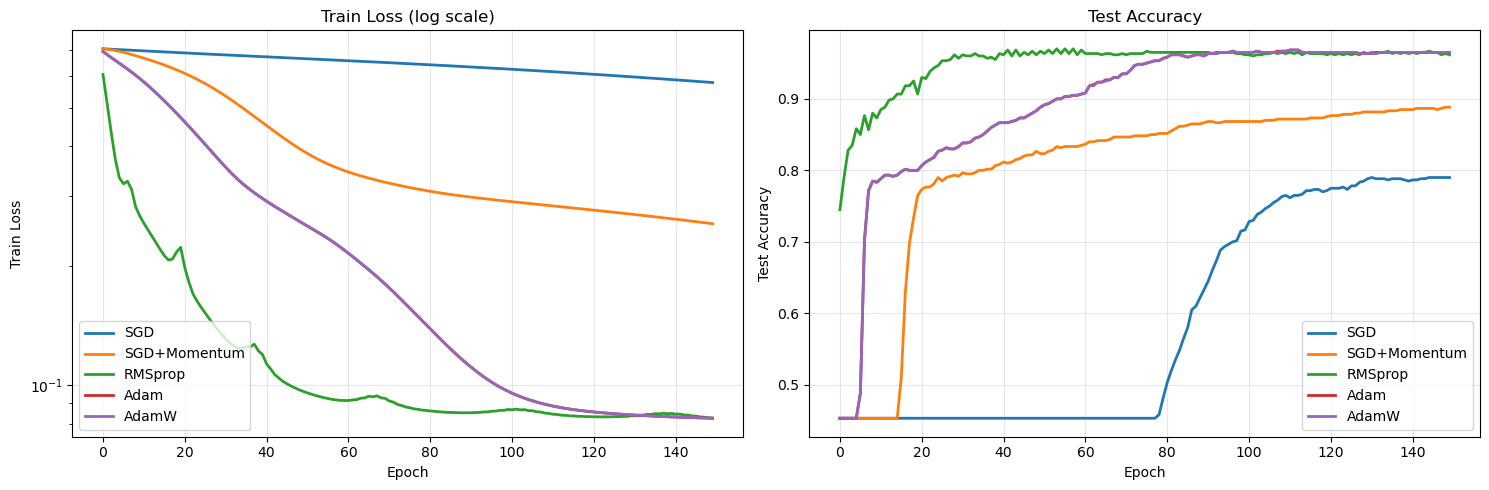

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ---- Train Loss ----
for name, h in results.items():
    axes[0].plot(h["epoch"], h["train_loss"], label=name, linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Train Loss")
axes[0].set_title("Train Loss (log scale)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ---- Test Accuracy ----
for name, h in results.items():
    axes[1].plot(h["epoch"], h["test_acc"], label=name, linewidth=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test Accuracy")
axes[1].set_title("Test Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. جدول ملخص الأرقام

In [10]:
summary = []
for name, h in results.items():
    summary.append({
        "Optimizer": name,
        "Final Train Loss": round(h["train_loss"][-1], 5),
        "Final Test Loss":  round(h["test_loss"][-1], 5),
        "Final Test Acc":   round(h["test_acc"][-1], 4),
        "Best Test Acc":    round(max(h["test_acc"]), 4),
        "Time (s)":         round(times[name], 2),
        "Epochs to 95% acc": next(
            (e for e, a in zip(h["epoch"], h["test_acc"]) if a >= 0.95), 
            "never"
        )
    })

df = pd.DataFrame(summary).sort_values("Final Test Acc", ascending=False)
df

,Optimizer,Final Train Loss,Final Test Loss,Final Test Acc,Best Test Acc,Time (s),Epochs to 95% acc
4,AdamW,0.08258,0.09315,0.9650,0.9683,0.18,75
3,Adam,0.08256,0.09314,0.9650,0.9683,0.21,75
2,RMSprop,0.08269,0.09502,0.9617,0.9700,0.20,25
1,SGD+Momentum,0.25499,0.25238,0.8883,0.8883,0.17,never
0,SGD,0.57806,0.58928,0.7900,0.7900,0.39,never


## 7. الـ Decision Boundary لكل Optimizer
عشان نشوف شكل الحل اللي كل واحد وصله.

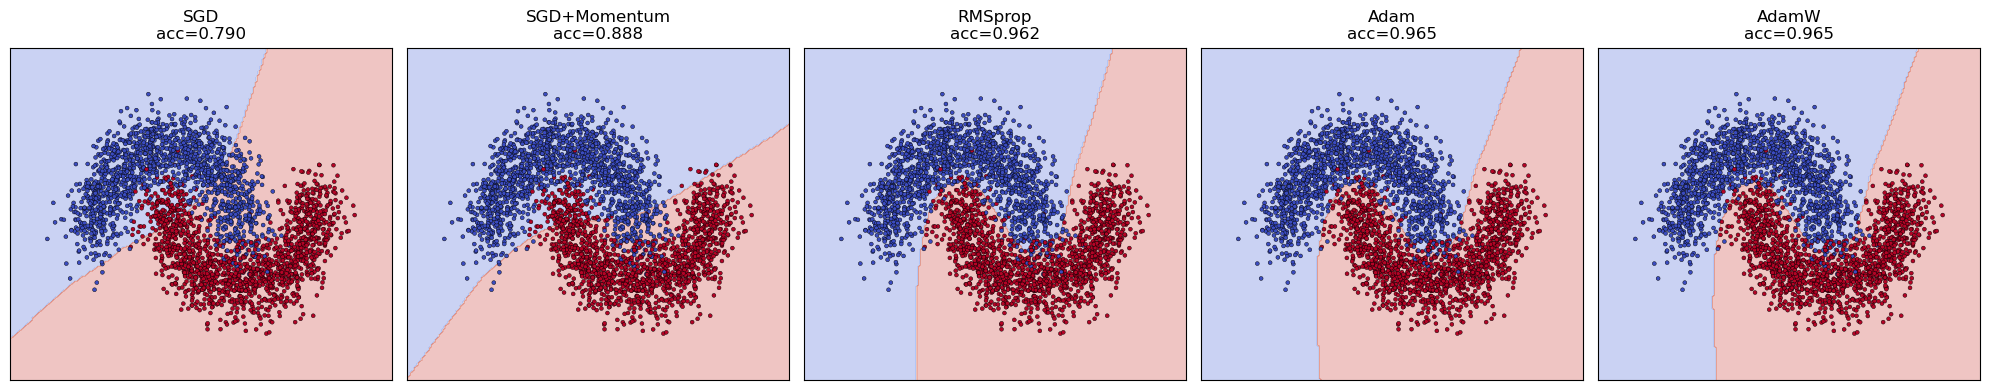

In [11]:
def plot_decision_boundary(model, X, y, ax, title):
    # شبكة على كامل المساحة
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )
    grid = torch.FloatTensor(np.c_[xx.ravel(), yy.ravel()]).to(DEVICE)
    
    model.eval()
    with torch.no_grad():
        preds = model(grid).argmax(1).cpu().numpy().reshape(xx.shape)
    
    ax.contourf(xx, yy, preds, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=8, edgecolors="k", linewidths=0.3)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, len(OPTIMIZER_NAMES), figsize=(4*len(OPTIMIZER_NAMES), 4))
for ax, name in zip(axes, OPTIMIZER_NAMES):
    acc = results[name]["test_acc"][-1]
    plot_decision_boundary(models[name], X_all, y_all, ax, f"{name}\nacc={acc:.3f}")
plt.tight_layout()
plt.show()

## 8. تجربة: Adam حساس للـ LR؟
هنشغل Adam بـ lr مختلفة ونشوف إمتى ينفجر.

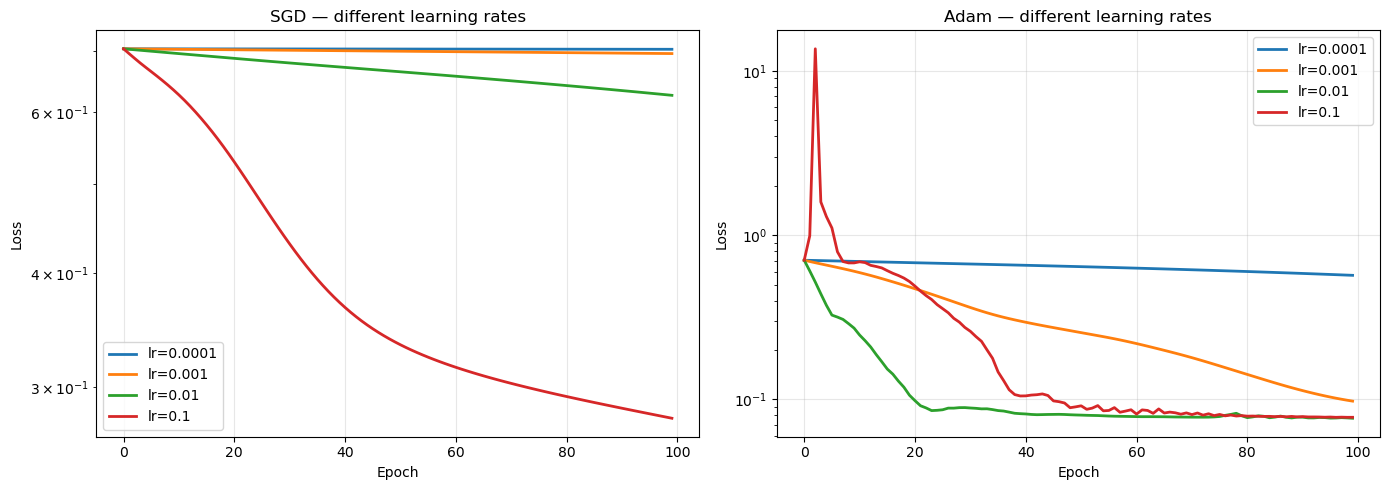

In [12]:
def train_with_lr(name, lr, epochs=100):
    model = make_model()
    if name == "Adam":
        opt = optim.Adam(model.parameters(), lr=lr)
    elif name == "SGD":
        opt = optim.SGD(model.parameters(), lr=lr)
    else:
        raise ValueError
    criterion = nn.CrossEntropyLoss()
    losses = []
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        loss = criterion(model(X_train), y_train)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

lrs = [0.0001, 0.001, 0.01, 0.1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, opt_name in zip(axes, ["SGD", "Adam"]):
    for lr in lrs:
        losses = train_with_lr(opt_name, lr, epochs=100)
        ax.plot(losses, label=f"lr={lr}", linewidth=2)
    ax.set_title(f"{opt_name} — different learning rates")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_yscale("log")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. الخلاصة

### اللي هنلاحظه من التجارب:

| Optimizer | الملاحظة |
|-----------|----------|
| **SGD** | أبطأ واحد، حساس جداً للـ lr |
| **SGD+Momentum** | أسرع من SGD، ثابت أكتر |
| **RMSprop** | متوسط، بيشتغل كويس بس مش الأفضل هنا |
| **Adam** | أسرع تقارب، ثابت حتى مع lr كبيرة نسبياً |
| **AdamW** | زي Adam بس generalization أحسن (مش هيبان قوي في مشكلة صغيرة زي دي) |

### امتى تستخدم إيه؟
- **Adam/AdamW**: الافتراضي لأي مشكلة جديدة. LLMs, Transformers, NLP.
- **SGD+Momentum**: لو عايز آخر شوية accuracy في CV (ResNet, ImageNet).
- **RMSprop**: RNNs و RL.
- **SGD**: بس في أوراق بحثية للمقارنة.

### ليه Adam هو السائد؟
1. Adaptive LR لكل باراميتر → مش محتاج tuning كتير
2. سريع في البداية
3. شغال على كل المعماريات
4. الـ Transformers كلها بتستخدم AdamW